In [346]:
import numpy as np
import matplotlib.pyplot as plt

In [347]:
class ConditionedBridge:
    
    def __init__(self):
        self.cache = dict()
        
    def condition(self, A):
        A_11 = A[:-1, :-1]
        A_21 = A[-1:, :-1]
        A_12 = A[:-1, -1:]
        A_22 = A[-1:, -1:]
        A_22i = np.linalg.inv(A_22)

        A_transformer = A_12 @ A_22i
        A_bar = A_11 - A_transformer @ A_21
        return A_bar, A_transformer
        
    def get(self, L, endpoint, enddiff, RNG_block_name, RNG_correlation, RNG):
        
        if L in self.cache:
            SIG1_TRANSF = self.cache[L]['SIG1_TRANSF']
            SIG2_TRANSF = self.cache[L]['SIG2_TRANSF']
            SIG2_BAR_CHOLESKY = self.cache[L]['SIG2_BAR_CHOLESKY']
            STD1 = self.cache[L]['STD1']
            STD2 = self.cache[L]['STD2']
        
        else:
            SIG0 = np.eye(L-1)
            INT  = np.tril(np.ones((L-1, L-1)))
            SIG1 = INT @ SIG0 @ INT.T
            
            STD1 = np.sqrt(SIG1[-1,-1])
            
            SIG1_BAR, SIG1_TRANSF = self.condition(SIG1)
            
            INT  = np.tril(np.ones((L-2, L-2)))
            SIG2 = INT @ SIG1_BAR @ INT.T
            STD2 = np.sqrt(SIG2[-1,-1])
            
            SIG2_BAR, SIG2_TRANSF = self.condition(SIG2)
            SIG2_BAR_CHOLESKY = np.linalg.cholesky(SIG2_BAR)
            
            self.cache[L] = dict(SIG1_TRANSF=SIG1_TRANSF, SIG2_TRANSF=SIG2_TRANSF, SIG2_BAR_CHOLESKY=SIG2_BAR_CHOLESKY, STD1=STD1, STD2=STD2)
        
        MU1_BAR = SIG1_TRANSF * enddiff
        MU2  = np.cumsum(MU1_BAR, axis=0) # Same as INT
        MU2_BAR = MU2[:-1, :] + SIG2_TRANSF @ (endpoint - enddiff - MU2[-1:, -1:])
        w = np.random.randn(*MU2_BAR.shape)
        W = SIG2_BAR_CHOLESKY @ w + MU2_BAR
        W = np.concatenate((0 * endpoint[None, :], W, endpoint[None, :]-enddiff[None, :], endpoint[None, :]))
        
        return dict(mu=MU2_BAR, w=W, std1=STD1, std2=STD2)

In [348]:
Gen = ConditionedBridge()

22.338307903688676
3217.802044874731


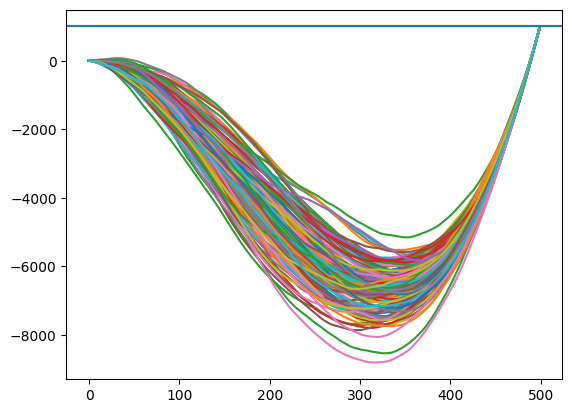

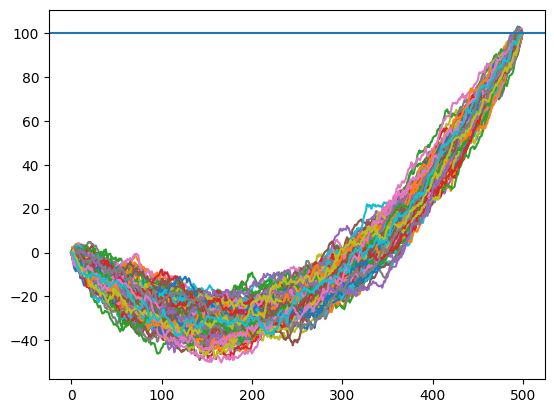

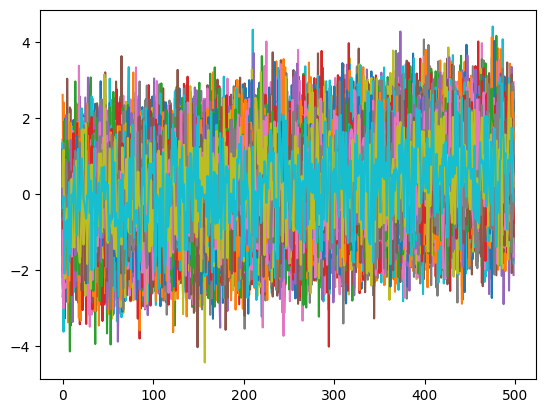

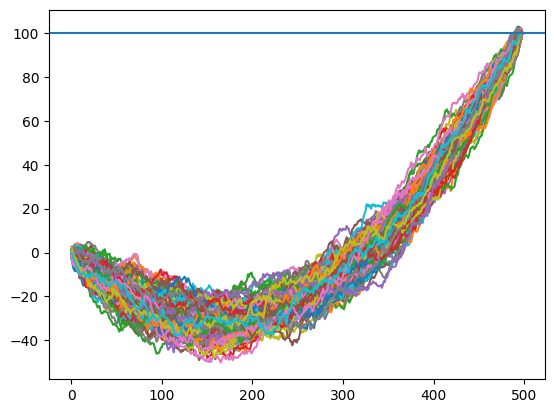

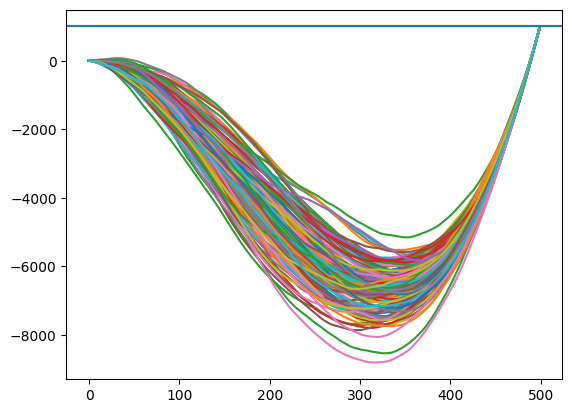

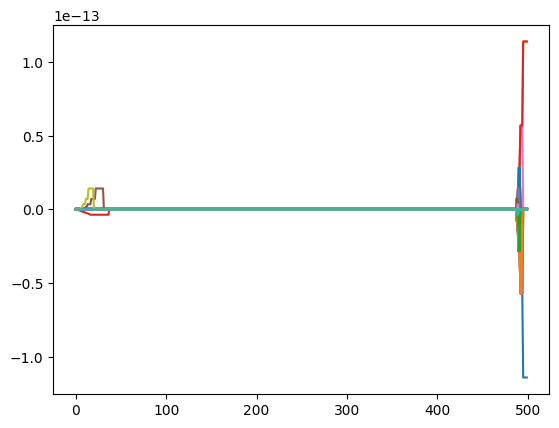

In [353]:
enddiff  = 100
endpoint = 1000

res = Gen.get(500, endpoint*np.ones(150), enddiff*np.ones(150), 'test', 0.99, None)
w = res['w']
dw = np.diff(w, axis=0)
dw = np.concatenate([w[[0],:], dw])

ddw = np.diff(dw, axis=0)
ddw_prepend = np.concatenate([dw[[0],:], ddw])

print(res['std1'])
print(res['std2'])

plt.plot(w)
plt.axhline(endpoint)
plt.show()

plt.plot(dw)
plt.axhline(enddiff)
plt.show()

plt.plot(ddw)
plt.show()

plt.plot(np.cumsum(ddw, axis=0))
plt.axhline(enddiff)
plt.show()

plt.plot(np.cumsum(dw, axis=0))
plt.axhline(endpoint)
plt.show()

plt.plot(np.cumsum(np.cumsum(ddw_prepend, axis=0), axis=0) - w)
plt.show()

In [350]:
locals().update(dict(a=2))

In [295]:
a

2